# KelpAdam – UAS Pembelajaran Mesin
## Notebook A – Klasifikasi Preferensi Belajar (VARK)

**Tujuan:** membangun model klasifikasi yang memprediksi **satu kategori preferensi belajar VARK** dari jawaban 16 skenario, lalu membandingkan **Support Vector Machine (SVM)** dan **Random Forest Classifier** secara adil, dengan baseline sebagai patokan.

| Komponen | Isi |
|---|---|
| Sumber data | `dataset/processed_UTS/KelpAdam_survey_prepared.csv` (hasil notebook UTS, 192 responden) |
| Framework | VARK: 64 indikator 0/1 dari 16 skenario |
| Target y | `VARK_label`: Visual / Aural / Read/Write / Kinesthetic / Seri |
| Pembagian data | train 80% : test 20%, `random_state = 42`, stratifikasi berdasarkan y |
| Model | Baseline (kelas terbanyak), SVM, Random Forest |
| Metrik | Accuracy, macro-F1, confusion matrix, analisis contoh salah prediksi |

**Alur notebook:** A0 Setup → A1 Data, definisi X/y & aturan label → A2 Preprocessing & cleaning → A3 EDA → A4 Split & pipeline → A5 Training & pemilihan model → A6 Evaluasi test → A7 Simpan model.

**Batas interpretasi (spesifikasi UAS §2):** label y dihitung **langsung** dari jawaban yang juga menjadi X. Jadi model di notebook ini belajar **meniru aturan skoring**, bukan membuktikan bahwa gaya belajar VARK itu ada atau lebih unggul. Kategori **Seri** hanyalah aturan operasional tugas, bukan gaya belajar kelima.

---
# A0 – Setup

Semua library, konstanta, dan path didefinisikan di satu sel supaya notebook bisa dijalankan ulang dari awal (*Restart & Run All*). Struktur dan konstanta sama dengan Notebook B (regresi), sehingga kedua notebook konsisten.

In [1]:
import json
import platform
import time
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# --- Konstanta eksperimen (sesuai spesifikasi UAS) ---
SEED = 42          # random_state wajib
TEST_SIZE = 0.2    # train : test = 80 : 20

# --- Path relatif: notebook berada di <folder proyek>/notebook/ ---
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_FILE = PROJECT_DIR / "dataset" / "processed_UTS" / "KelpAdam_survey_prepared.csv"
DATA_OUT  = PROJECT_DIR / "dataset" / "processed_UAS"     # Dataset_klasifikasi.csv
MODEL_DIR = PROJECT_DIR / "models"                        # Model_klasifikasi.joblib
OUT_DIR   = PROJECT_DIR / "figures_and_outputs"           # grafik & tabel (prefix A)
for folder in (DATA_OUT, MODEL_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Tampilan tabel & grafik ---
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BIRU, ORANYE, ABU = "#2b6cb0", "#dd6b20", "#a0aec0"


def simpan_fig(fig, nama):
    """Simpan grafik ke figures_and_outputs/<nama>.png lalu tampilkan."""
    path = OUT_DIR / f"{nama}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    plt.show()
    print("Disimpan:", path.relative_to(PROJECT_DIR))


def simpan_tabel(tabel, nama):
    """Simpan tabel ke figures_and_outputs/<nama>.csv agar angka laporan bisa ditelusuri."""
    path = OUT_DIR / f"{nama}.csv"
    tabel.to_csv(path)
    print("Disimpan:", path.relative_to(PROJECT_DIR))


print("Folder proyek :", PROJECT_DIR)
print("File data     :", DATA_FILE.relative_to(PROJECT_DIR), "| ada?", DATA_FILE.exists())
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | joblib {joblib.__version__}")

Folder proyek : d:\Kuliah\Semester 5\Machine Learning\KelpAdam_UAS_MachineLearning
File data     : dataset\processed_UTS\KelpAdam_survey_prepared.csv | ada? True
Python 3.12.10 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | joblib 1.6.0


---
# A1 – Memuat data, mendefinisikan X dan y, dan aturan label

## A1.1 Memuat dataset hasil UTS
Panduan UAS: *UAS menggunakan dataset yang dihasilkan pada UTS.* Dataset ini sudah melalui cleaning C1–C10 di notebook UTS (194 → 192 baris) dan berisi item mentah, skor, label, serta 64 indikator VARK. File UTS hanya **dibaca**, tidak diubah.

In [2]:
df = pd.read_csv(DATA_FILE)
print("Ukuran dataset:", df.shape)
assert df.shape == (192, 216), "Ukuran berbeda dari output UTS; periksa file di dataset/processed_UTS/"
assert df["ID"].is_unique, "ID tidak unik"
display(df[["ID", "VARK_Q01", "VARK_Q01_V", "VARK_Q01_A", "VARK_Q01_R", "VARK_Q01_K", "VARK_label"]].head(3))

Ukuran dataset: (192, 216)


,ID,VARK_Q01,VARK_Q01_V,VARK_Q01_A,VARK_Q01_R,VARK_Q01_K,VARK_label
0,1,"melihat diagram, bagan, peta konsep, atau ilus...",1,1,0,0,Seri
1,2,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1,Visual
2,3,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1,Visual


## A1.2 Alasan memilih framework VARK
Distribusi label keempat framework (hasil scoring UTS, n = 192) menjadi pertimbangan utama, karena model klasifikasi butuh kelas yang cukup terwakili.

| Framework | Distribusi label | Kategori teknis (Seri/Setara/Batas) | Catatan |
|---|---|---|---|
| **VARK** | Kinesthetic 51, Aural 42, Visual 38, Read/Write 31, Seri 30 | 16% | **Paling seimbang**; format pilihan, tidak terdampak straightliner |
| Felder–Silverman | Active 67, Reflective 64, Setara 61 | 32% | Seimbang, tetapi seluruh 15 straightliner jatuh ke Setara |
| Honey–Mumford | Seri 64, Pragmatist 43, Reflector 36, Theorist 31, Activist 18 | 33% | **Didominasi Seri**; Activist hanya 18 |
| Kolb | Batas 70, CE_RO 42, CE_AE 32, AC_RO 30, AC_AE 18 | 36% | **Didominasi Batas**; AC_AE hanya 18 |

**Keputusan:** VARK dipilih karena (1) label paling seimbang dan kategori Seri paling sedikit, (2) tidak terdampak 15 responden yang menjawab seragam di skala 1–5 (UTS C9), (3) 64 indikator sudah dibuat dan diverifikasi di UTS, dan (4) sama dengan framework Notebook B, sehingga aplikasi Streamlit cukup memakai satu form input untuk kedua tab.

## A1.3 Definisi fitur X dan target y

- **X** = 64 kolom `VARK_Qxx_M`: `xx` = nomor skenario 01–16, `M` = modalitas V (Visual, opsi A), A (Aural, opsi B), R (Read/Write, opsi C), K (Kinesthetic, opsi D), sesuai Lampiran panduan. Nilai **1 = opsi dipilih**, **0 = tidak dipilih**. Satu skenario boleh punya lebih dari satu angka 1.
- **y** = `VARK_label`, satu kategori dari 5 kemungkinan: Visual, Aural, Read/Write, Kinesthetic, atau Seri.
- **Urutan kolom X dikunci** di `FEATURE_COLS` (sama persis dengan Notebook B), dan wajib dipakai aplikasi Streamlit.

In [3]:
MODALITAS = ["V", "A", "R", "K"]   # urutan opsi A, B, C, D pada instrumen
NAMA_MOD = {"V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
FEATURE_COLS = [f"VARK_Q{q:02d}_{m}" for q in range(1, 17) for m in MODALITAS]
TARGET = "VARK_label"
KELAS = ["Visual", "Aural", "Read/Write", "Kinesthetic", "Seri"]   # urutan tetap untuk tabel & confusion matrix

assert len(FEATURE_COLS) == 64
kolom_hilang = [c for c in FEATURE_COLS if c not in df.columns]
assert not kolom_hilang, f"Kolom fitur tidak ditemukan: {kolom_hilang}"
assert set(df[TARGET].dropna().unique()) == set(KELAS), "Kategori label tidak sesuai panduan"

print(f"Jumlah fitur X : {len(FEATURE_COLS)} (16 skenario x 4 modalitas)")
print("Target y       :", TARGET, "| kategori:", KELAS)

Jumlah fitur X : 64 (16 skenario x 4 modalitas)
Target y       : VARK_label | kategori: ['Visual', 'Aural', 'Read/Write', 'Kinesthetic', 'Seri']


## A1.4 Kolom yang tidak dipakai sebagai fitur
Spesifikasi melarang memasukkan **ID, IPS, dan IPK** ke fitur klasifikasi. Panduan Klasifikasi juga melarang memakai **skor penyusun label** (`VARK_V/A/R/K/total`), label itu sendiri, dan item framework lain sebagai fitur tambahan. Sel berikut mengelompokkan seluruh 216 kolom beserta alasannya, lalu memastikan dengan `assert` bahwa X hanya berisi 64 indikator VARK.

In [4]:
SKOR_VARK = ["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]

def peran_kolom(kolom):
    """Kembalikan (kelompok, alasan) untuk setiap kolom dataset UTS."""
    if kolom == "ID":
        return "Identifier", "Nomor urut; hanya untuk melacak baris"
    if kolom == TARGET:
        return "Target y", "Label VARK dari aturan skoring panduan"
    if kolom in FEATURE_COLS:
        return "Fitur X", "Indikator VARK 0/1"
    if kolom.startswith("IPS_") or kolom == "IPK":
        return "IPS & IPK", "Dilarang sebagai fitur klasifikasi (spesifikasi §1)"
    if kolom in SKOR_VARK:
        return "Skor VARK (penyusun label)", "Dilarang; label dihitung dari skor ini (bocor)"
    if kolom.endswith("_label"):
        return "Label framework lain", "Bukan target; tidak boleh jadi fitur"
    if kolom.startswith("VARK_Q"):
        return "Teks jawaban VARK", "Sudah diwakili 64 indikator; teks disimpan untuk audit"
    if kolom.startswith(("HM_", "FS_", "KOLB_")):
        return "Framework lain (item & skor)", "X hanya dari satu framework"
    return "Variabel bantu UTS", "Konteks/kualitas data (angkatan, flag), bukan item survei"

peran = pd.DataFrame([(c, *peran_kolom(c)) for c in df.columns], columns=["kolom", "kelompok", "alasan"])
ringkas_peran = (peran.groupby(["kelompok", "alasan"], sort=False)
                 .agg(jumlah_kolom=("kolom", "size"), contoh=("kolom", lambda s: ", ".join(s[:3])))
                 .reset_index().set_index("kelompok"))
display(ringkas_peran)

assert ringkas_peran["jumlah_kolom"].sum() == df.shape[1] == 216
assert peran.loc[peran["kelompok"] == "Fitur X", "kolom"].tolist() == FEATURE_COLS
assert not set(FEATURE_COLS) & set(SKOR_VARK + ["ID", "IPK", TARGET])
print("OK: X hanya berisi 64 indikator VARK; ID, IPS, IPK, skor, label, dan framework lain tidak masuk X.")

,alasan,jumlah_kolom,contoh
kelompok,,,
Identifier,Nomor urut; hanya untuk melacak baris,1,ID
IPS & IPK,Dilarang sebagai fitur klasifikasi (spesifikas...,10,"IPS_2022_S1, IPS_2022_S2, IPS_2023_S1"
Teks jawaban VARK,Sudah diwakili 64 indikator; teks disimpan unt...,16,"VARK_Q01, VARK_Q02, VARK_Q03"
Framework lain (item & skor),X hanya dari satu framework,110,"HM_ACT_01, HM_ACT_02, HM_ACT_03"
Skor VARK (penyusun label),Dilarang; label dihitung dari skor ini (bocor),5,"VARK_V, VARK_A, VARK_R"
Target y,Label VARK dari aturan skoring panduan,1,VARK_label
Label framework lain,Bukan target; tidak boleh jadi fitur,3,"FS_ACT_REF_label, HM_label, KOLB_label"
Variabel bantu UTS,"Konteks/kualitas data (angkatan, flag), bukan ...",6,"angkatan_inferred, n_semester_ips, row_sd"
Fitur X,Indikator VARK 0/1,64,"VARK_Q01_V, VARK_Q01_A, VARK_Q01_R"


OK: X hanya berisi 64 indikator VARK; ID, IPS, IPK, skor, label, dan framework lain tidak masuk X.


## A1.5 Aturan pembentukan label dan verifikasi (Panduan Klasifikasi §6)

| Langkah | Aturan |
|---|---|
| 1. Skor per modalitas | Jumlahkan 16 indikator setiap modalitas → skor V, A, R, K (masing-masing 0–16). Karena pilihan bisa jamak, total keempat skor bisa lebih dari 16 |
| 2. Label | Label = modalitas dengan skor **tertinggi yang unik** |
| 3. Seri | Kalau dua atau lebih modalitas berbagi skor tertinggi yang sama, label = **Seri** |

Label sudah dihitung di UTS (S1). Sel berikut **menghitung ulang** label dari 64 indikator dengan aturan di atas, lalu membuktikan hasilnya sama dengan `VARK_label` untuk seluruh 192 responden. Skor V/A/R/K di sini hanya untuk verifikasi dan analisis, **tidak** dipakai sebagai fitur.

In [5]:
def skor_vark(X_ind):
    """Skor V, A, R, K = jumlah 16 indikator per modalitas."""
    return pd.DataFrame({m: X_ind[[f"VARK_Q{q:02d}_{m}" for q in range(1, 17)]].sum(axis=1) for m in MODALITAS})

def label_vark(skor):
    """Modalitas dengan skor tertinggi yang unik; kalau ada yang sama tinggi -> 'Seri'."""
    maks = skor.max(axis=1)
    jumlah_maks = skor.eq(maks, axis=0).sum(axis=1)
    return np.where(jumlah_maks > 1, "Seri", skor.idxmax(axis=1).map(NAMA_MOD))

skor = skor_vark(df[FEATURE_COLS])
label_ulang = pd.Series(label_vark(skor), index=df.index)

# Verifikasi terhadap hasil UTS
assert (skor.values == df[["VARK_V", "VARK_A", "VARK_R", "VARK_K"]].values).all(), "Skor berbeda dengan UTS"
n_beda_label = int((label_ulang != df[TARGET]).sum())
assert n_beda_label == 0, "Label hasil hitung ulang berbeda dengan UTS"
print(f"OK: skor dan label hasil hitung ulang identik dengan UTS untuk {len(df)} responden (label berbeda: {n_beda_label}).")

# Tabel audit: skor V/A/R/K, selisih skor tertinggi - kedua, dan jumlah modalitas yang sama tinggi
urut_skor = np.sort(skor.values, axis=1)
selisih_teratas = urut_skor[:, -1] - urut_skor[:, -2]
jumlah_tertinggi = skor.eq(skor.max(axis=1), axis=0).sum(axis=1)
tabel_audit = pd.DataFrame({"ID": df["ID"], "skor_V": skor["V"], "skor_A": skor["A"], "skor_R": skor["R"],
                            "skor_K": skor["K"], "selisih_tertinggi_kedua": selisih_teratas,
                            "jumlah_modalitas_tertinggi": jumlah_tertinggi, "VARK_label": df[TARGET]}).set_index("ID")
simpan_tabel(tabel_audit, "A1_tabel_audit_skor_label")   # untuk audit saja, BUKAN dataset modeling

# Contoh verifikasi manual: kelas tunggal, menang tipis, Seri 2 modalitas, Seri 3 modalitas, dan Seri 4 modalitas (ID 55)
contoh_id = [df.loc[(df[TARGET] == "Kinesthetic") & (selisih_teratas >= 5), "ID"].iloc[0],
             df.loc[(df[TARGET] != "Seri") & (selisih_teratas == 1), "ID"].iloc[0],
             df.loc[(df[TARGET] == "Seri") & (jumlah_tertinggi == 2), "ID"].iloc[0],
             df.loc[(df[TARGET] == "Seri") & (jumlah_tertinggi == 3), "ID"].iloc[0],
             df.loc[(df[TARGET] == "Seri") & (jumlah_tertinggi == 4), "ID"].iloc[0]]
contoh = tabel_audit.loc[contoh_id]
contoh.columns = ["skor V", "skor A", "skor R", "skor K", "selisih tertinggi - kedua",
                  "jumlah modalitas tertinggi", "label (UTS)"]
display(contoh)

OK: skor dan label hasil hitung ulang identik dengan UTS untuk 192 responden (label berbeda: 0).
Disimpan: figures_and_outputs\A1_tabel_audit_skor_label.csv


,skor V,skor A,skor R,skor K,selisih tertinggi - kedua,jumlah modalitas tertinggi,label (UTS)
ID,,,,,,,
4,4,3,4,15,11,1,Kinesthetic
6,6,0,6,7,1,1,Kinesthetic
1,12,12,7,0,0,2,Seri
81,7,7,7,2,0,3,Seri
55,16,16,16,16,0,4,Seri


**Cara membaca contoh verifikasi:** di setiap baris, cari skor tertinggi di antara V/A/R/K. Kalau hanya satu modalitas yang tertinggi, itulah labelnya. Kalau ada dua atau lebih yang sama tinggi, labelnya Seri.
- **ID 4:** Kinesthetic menang jauh (15 vs 4, selisih 11).
- **ID 6:** Kinesthetic menang tipis (7 vs 6, selisih 1).
- **ID 1, 81, 55:** Seri dengan 2, 3, dan 4 modalitas yang sama tinggi. ID 55 memilih keempat opsi di semua skenario, sehingga keempat skor sama-sama 16.

Kolom **selisih tertinggi – kedua** menunjukkan seberapa tipis kemenangannya (0 = Seri, 1 = menang tipis). Kolom ini dipakai lagi di analisis kesalahan A6, karena responden yang skornya hampir seri diperkirakan paling sulit ditebak model.

Seluruh skor, selisih, dan label 192 responden disimpan sebagai **tabel audit** di `figures_and_outputs/A1_tabel_audit_skor_label.csv`, sesuai Panduan §7 (*"Simpan tabel bantu skor/selisih untuk audit"*). Tabel ini **bukan** dataset modeling dan isinya tidak dipakai sebagai fitur.

**Ringkasan A1:**
- Dataset UTS terbaca utuh: **192 baris × 216 kolom**.
- **X = 64 indikator VARK** dengan urutan terkunci; **y = `VARK_label`** dengan 5 kategori.
- ID, IPS, IPK, skor penyusun label, label lain, dan framework lain dikeluarkan, dibuktikan dengan `assert`.
- Label dihitung ulang dengan aturan panduan dan **identik** dengan UTS untuk 192 responden; 5 contoh manual (kelas tunggal, menang tipis, Seri 2/3/4 modalitas) ditampilkan, dan tabel audit skor disimpan ke CSV.

---
# A2 – Preprocessing & justifikasi cleaning

Cleaning utama sudah dikerjakan di notebook UTS (C2: hapus 2 respons kosong total, 194 → 192; C4: validasi opsi VARK terhadap daftar resmi; C9: flag responden berpola seragam). Di bagian ini data dicek ulang **khusus untuk klasifikasi**.

**Catatan:** belum ada transformasi yang *belajar dari data* (scaling, imputasi). Semua itu dilakukan di dalam pipeline **setelah** split (A4), supaya tidak terjadi *data leakage*.

## A2.0 Verifikasi pengodean VARK (Panduan Klasifikasi §6, langkah 1–3)
Panduan meminta: (1) pecah teks per titik koma, (2) cocokkan setiap teks dengan opsi Lampiran (A = Visual, B = Aural, C = Read/Write, D = Kinesthetic), (3) buat 4 indikator 0/1 per skenario. **Sel kosong disimpan sebagai missing, bukan empat nol.** Sel berikut membuat ulang pengodean dari 16 kolom teks jawaban dan membuktikan hasilnya identik dengan 64 indikator UTS. Fungsi `encode_vark` ini sama dengan yang dipakai Notebook B dan aplikasi Streamlit.

In [6]:
# Teks opsi resmi per skenario, urutan [A=Visual, B=Aural, C=Read/Write, D=Kinesthetic] (Lampiran Panduan)
VARK_OPSI = {
    1: ["melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.",
        "mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.",
        "membaca uraian tertulis, definisi, atau catatan yang terstruktur.",
        "mencoba contoh, simulasi, praktik, atau melihat penerapan nyata."],
    2: ["mengikuti gambar langkah demi langkah atau tangkapan layar.",
        "meminta seseorang menjelaskan langkah-langkahnya secara lisan.",
        "membaca petunjuk tertulis dan daftar langkah.",
        "langsung mencoba sambil memperbaiki kesalahan yang muncul."],
    3: ["membuat peta konsep, skema, warna, atau diagram.",
        "menjelaskan materi dengan suara keras atau berdiskusi dengan teman.",
        "menulis ulang ringkasan, membuat daftar, atau membaca catatan.",
        "berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman."],
    4: ["ada visualisasi yang menunjukkan hubungan antar konsep.",
        "penjelasan disampaikan dengan contoh verbal dan tanya jawab.",
        "tersedia teks atau rumusan tertulis yang dapat saya baca kembali.",
        "ada demonstrasi, studi kasus, atau aktivitas langsung."],
    5: ["melihat contoh hasil akhir atau struktur visual tugas.",
        "mendengarkan penjelasan dosen tentang apa yang harus dilakukan.",
        "membaca instruksi dan rubrik secara rinci.",
        "mencoba bagian awal tugas untuk memahami apa yang diminta."],
    6: ["melihat peta atau petunjuk arah visual.",
        "bertanya kepada orang lain dan mendengarkan arahannya.",
        "membaca nama jalan, papan petunjuk, atau instruksi tertulis.",
        "berjalan mencoba rute sambil menyesuaikan arah."],
    7: ["grafik, diagram, dan visualisasi pola.",
        "penjelasan lisan tentang makna hasil.",
        "tabel, uraian tertulis, dan penjelasan metodologis.",
        "contoh penerapan data pada kasus nyata."],
    8: ["menggambar skema atau menunjukkan visual.",
        "menjelaskannya melalui percakapan.",
        "menuliskan poin-poin atau memberi bacaan singkat.",
        "menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi."],
    9: ["infografik, diagram, atau video dengan visual yang jelas.",
        "rekaman audio, diskusi sinkron, atau penjelasan verbal.",
        "modul teks, transkrip, dan catatan yang lengkap.",
        "simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus."],
    10: ["membuat sketsa atau memetakan masalah secara visual.",
         "membicarakan masalah dengan orang lain untuk memperoleh ide.",
         "menuliskan fakta, alternatif, dan langkah pemecahan.",
         "mencoba beberapa solusi dan belajar dari hasil percobaan."],
    11: ["video animasi, diagram interaktif, atau infografik.",
         "podcast, rekaman kuliah, atau diskusi kelompok.",
         "artikel, buku, modul, atau catatan tertulis.",
         "tutorial praktik, proyek, eksperimen, atau studi kasus."],
    12: ["dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.",
         "dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.",
         "dapat menuliskan definisi dan penjelasannya secara runtut.",
         "dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata."],
    13: ["mencari bagian visual terlebih dahulu untuk memahami gambaran besar.",
         "mendengarkan penjelasan terkait sebelum atau sambil belajar.",
         "membaca dan membuat catatan secara sistematis.",
         "mencari latihan atau contoh penerapan setelah memahami pokok materi."],
    14: ["ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.",
         "dibicarakan secara langsung sehingga saya dapat bertanya.",
         "diberikan komentar tertulis yang rinci.",
         "diberi kesempatan mencoba revisi dan melihat dampaknya."],
    15: ["menyusun bagan, desain, atau struktur visual.",
         "berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.",
         "menulis dokumen, rangkuman, atau notulen.",
         "mengerjakan prototipe, praktik, atau implementasi."],
    16: ["melihat representasi visual tentang bagaimana hal itu bekerja.",
         "mendengar seseorang menjelaskannya dan berdialog.",
         "membaca penjelasan tertulis yang lengkap.",
         "mengalami atau mencoba secara langsung."],
}
assert len(VARK_OPSI) == 16 and all(len(v) == 4 for v in VARK_OPSI.values())


def normalisasi(teks):
    """Samakan format teks: huruf kecil, spasi tunggal, tanpa titik di akhir."""
    return " ".join(str(teks).lower().split()).rstrip(".")


# Peta teks opsi -> modalitas, per skenario
PETA_OPSI = {q: {normalisasi(t): m for t, m in zip(opsi, MODALITAS)} for q, opsi in VARK_OPSI.items()}


def encode_vark(jawaban):
    """Ubah 16 jawaban teks VARK menjadi 64 indikator 0/1.

    jawaban: list/Series berisi 16 teks (skenario 1-16); satu teks bisa memuat beberapa opsi dipisah ';'.
    Mengembalikan (indikator, tidak_cocok):
      - indikator  : dict 64 kolom; skenario kosong -> NaN (bukan empat nol)
      - tidak_cocok: list (skenario, token) yang tidak ada di daftar opsi resmi
    """
    indikator, tidak_cocok = {}, []
    for q, teks in zip(range(1, 17), jawaban):
        token = [] if pd.isna(teks) else [t for t in str(teks).split(";") if t.strip()]  # buang token kosong
        dipilih = set()
        for t in token:
            m = PETA_OPSI[q].get(normalisasi(t))
            if m is None:
                tidak_cocok.append((q, t.strip()))
            else:
                dipilih.add(m)
        for m in MODALITAS:
            indikator[f"VARK_Q{q:02d}_{m}"] = (1 if m in dipilih else 0) if token else np.nan
    return indikator, tidak_cocok

In [7]:
TEKS_COLS = [f"VARK_Q{q:02d}" for q in range(1, 17)]
hasil = [encode_vark(baris) for baris in df[TEKS_COLS].itertuples(index=False)]
X_encode = pd.DataFrame([h[0] for h in hasil], index=df.index)[FEATURE_COLS]
tidak_cocok = [(df.at[i, "ID"], q, t) for i, (_, tc) in zip(df.index, hasil) for q, t in tc]

n_skenario_kosong_teks = int(df[TEKS_COLS].isna().sum().sum())
n_beda = int((X_encode.fillna(-1) != df[FEATURE_COLS]).sum().sum())

display(pd.DataFrame({"Hasil": {
    "Responden diperiksa": len(df),
    "Skenario kosong (missing)": n_skenario_kosong_teks,
    "Token teks tidak cocok dengan opsi resmi": len(tidak_cocok),
    "Sel berbeda dengan 64 indikator UTS": n_beda,
}}))
assert n_skenario_kosong_teks == 0 and not tidak_cocok and n_beda == 0
print("OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.")

,Hasil
Responden diperiksa,192
Skenario kosong (missing),0
Token teks tidak cocok dengan opsi resmi,0
Sel berbeda dengan 64 indikator UTS,0


OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.


## A2.1 Validasi fitur X dan label
Yang dicek: tidak ada sel kosong, semua nilai 0/1, setiap skenario punya minimal satu opsi dipilih, dan setiap responden punya label.

In [8]:
X_semua = df[FEATURE_COLS]
n_nan = int(X_semua.isna().sum().sum())
n_bukan_biner = int((~X_semua.isin([0, 1])).sum().sum())
n_skenario_kosong = int(sum(
    (X_semua[[f"VARK_Q{q:02d}_{m}" for m in MODALITAS]].sum(axis=1) == 0).sum() for q in range(1, 17)))
n_label_kosong = int(df[TARGET].isna().sum())

display(pd.DataFrame({"Hasil": {
    "Tipe data fitur": ", ".join(sorted(X_semua.dtypes.astype(str).unique())),
    "Sel fitur kosong (NaN)": n_nan,
    "Nilai fitur selain 0/1": n_bukan_biner,
    "Skenario tanpa opsi dipilih": n_skenario_kosong,
    "Label kosong": n_label_kosong,
}}))
assert n_nan == n_bukan_biner == n_skenario_kosong == n_label_kosong == 0
print("OK: 64 fitur lengkap dan biner, setiap skenario dijawab, dan semua 192 responden punya label.")

,Hasil
Tipe data fitur,int64
Sel fitur kosong (NaN),0
Nilai fitur selain 0/1,0
Skenario tanpa opsi dipilih,0
Label kosong,0


OK: 64 fitur lengkap dan biner, setiap skenario dijawab, dan semua 192 responden punya label.


## A2.2 Duplikasi
Karena label dihitung dari X, dua responden dengan X identik **pasti** punya label yang sama. Mereka tetap dua orang berbeda (ID berbeda, jawaban skala 1–5 dan IPK berbeda), jadi tidak dihapus.

In [9]:
sama_x = df[df.duplicated(subset=FEATURE_COLS, keep=False)]
print("Duplikat ID       :", int(df["ID"].duplicated().sum()))
print("Baris dengan pola X identik:", len(sama_x))
display(sama_x[["ID", TARGET, "VARK_total", "IPK"]])

Duplikat ID       : 0
Baris dengan pola X identik: 2


,ID,VARK_label,VARK_total,IPK
113,115,Aural,16,3.57
121,123,Aural,16,2.95


**Temuan:** tidak ada duplikat ID. Ada 2 responden (ID 115 dan 123) dengan pola jawaban VARK yang persis sama, sehingga labelnya sama (Aural). IPK keduanya berbeda (3,57 vs 2,95), jadi mereka **orang berbeda** dan **dipertahankan**. *(`VARK_total` dan `IPK` hanya ditampilkan untuk audit, tidak dipakai sebagai fitur.)*

## A2.3 Responden berpola seragam (straightliner): dipertahankan
Flag `flag_straightline` dari UTS dibuat berdasarkan 88 item skala 1–5, **bukan** dari VARK. Sel berikut memeriksa jawaban VARK dan label mereka.

In [10]:
sl = df[df["flag_straightline"]]
print(f"Jumlah straightliner: {len(sl)}")
print(f"Jumlah opsi VARK yang dipilih (dari 64): min {sl['VARK_total'].min()}, "
      f"median {sl['VARK_total'].median():.0f}, max {sl['VARK_total'].max()}")
print("Label VARK mereka:", sl[TARGET].value_counts().to_dict())

Jumlah straightliner: 15
Jumlah opsi VARK yang dipilih (dari 64): min 16, median 32, max 64
Label VARK mereka: {'Aural': 6, 'Seri': 6, 'Read/Write': 2, 'Kinesthetic': 1}


**Keputusan:** ke-15 straightliner **dipertahankan**. Jumlah opsi VARK yang mereka pilih bervariasi (16 sampai 64) dan label mereka tersebar di beberapa kategori, jadi jawaban VARK mereka tidak seragam seperti jawaban skala 1–5. Panduan juga menyatakan bahwa label yang dapat dihitung tidak perlu dipaksakan atau dibuang. Satu kasus khusus: **ID 55** memilih keempat opsi di semua skenario, sehingga keempat skor sama (16) dan labelnya **Seri**. Ini sah menurut aturan panduan.

**Catatan:** 6 dari 15 straightliner (40%) berlabel **Seri**, jauh di atas proporsi Seri di seluruh data (16%). Ini sejalan dengan temuan di A3.2: responden yang memilih banyak opsi lebih mudah mendapat skor yang sama di beberapa modalitas.

## A2.4 Ringkasan cleaning & ekspor `Dataset_klasifikasi.csv`
Sesuai Panduan Klasifikasi §7 (*"Buat satu dataset X1, X2, ..., Xn dan satu kolom target y"*), `Dataset_klasifikasi.csv` hanya berisi **64 fitur X** dan **`VARK_label`**, tanpa ID dan tanpa skor penyusun label. Di dalam notebook, `ID` tetap disimpan terpisah untuk menelusuri contoh kesalahan di A6.

In [11]:
log_klasifikasi = pd.DataFrame([
    ("Dataset UTS (setelah cleaning C1-C10)", 192, 192, "Titik awal"),
    ("Skenario VARK kosong / teks tidak cocok", 192, 192, f"{n_skenario_kosong_teks} kosong, {len(tidak_cocok)} tidak cocok (A2.0)"),
    ("Label kosong", 192, 192 - n_label_kosong, f"{n_label_kosong} label kosong (A2.1)"),
    ("Pola X identik", 192, 192, f"{len(sama_x)} baris dipertahankan; orang berbeda (A2.2)"),
    ("Straightliner (skala 1-5)", 192, 192, f"{len(sl)} baris dipertahankan; jawaban VARK bervariasi (A2.3)"),
], columns=["langkah", "baris_sebelum", "baris_sesudah", "keterangan"]).set_index("langkah")
display(log_klasifikasi)
simpan_tabel(log_klasifikasi, "A2_log_cleaning_klasifikasi")

dataset_klasifikasi = df[FEATURE_COLS + [TARGET]].reset_index(drop=True)   # hanya X + y, tanpa ID
path_dataset = DATA_OUT / "Dataset_klasifikasi.csv"
dataset_klasifikasi.to_csv(path_dataset, index=False)

cek = pd.read_csv(path_dataset)
pd.testing.assert_frame_equal(cek, dataset_klasifikasi)
assert list(cek.columns) == FEATURE_COLS + [TARGET]
print("Disimpan:", path_dataset.relative_to(PROJECT_DIR), "| ukuran:", cek.shape, "(64 fitur + VARK_label)")

,baris_sebelum,baris_sesudah,keterangan
langkah,,,
Dataset UTS (setelah cleaning C1-C10),192,192,Titik awal
Skenario VARK kosong / teks tidak cocok,192,192,"0 kosong, 0 tidak cocok (A2.0)"
Label kosong,192,192,0 label kosong (A2.1)
Pola X identik,192,192,2 baris dipertahankan; orang berbeda (A2.2)
Straightliner (skala 1-5),192,192,15 baris dipertahankan; jawaban VARK bervarias...


Disimpan: figures_and_outputs\A2_log_cleaning_klasifikasi.csv
Disimpan: dataset\processed_UAS\Dataset_klasifikasi.csv | ukuran: (192, 65) (64 fitur + VARK_label)


**Ringkasan A2:**
- Pengodean VARK dibuktikan ulang sesuai panduan dan identik dengan UTS (A2.0).
- Fitur X bersih (64 kolom biner, 0 kosong, setiap skenario dijawab) dan **semua 192 responden punya label**. Tidak ada baris yang perlu dibuang dan tidak perlu imputasi.
- 2 responden dengan pola X identik dan 15 straightliner **dipertahankan** dengan alasan tertulis.
- `Dataset_klasifikasi.csv` (**192 × 65**: 64 fitur + label, tanpa ID) tersimpan di `dataset/processed_UAS/`.

---
# A3 – Exploratory Data Analysis (EDA)

Fokus EDA klasifikasi (rubrik A3): **distribusi target**, **kelas minoritas dan ketidakseimbangan kelas**, serta kaitannya dengan keputusan modeling. Pemeriksaan kualitas data (kosong, duplikat, nilai tidak valid) sudah dilakukan dan dibuktikan dengan `assert` di A1–A2, jadi tidak diulang.

**Catatan leakage:** EDA dilakukan pada 192 baris sebelum split dan bersifat **deskriptif saja**. Tidak ada keputusan fitur yang diambil dari EDA; seluruh 64 fitur tetap dipakai.

## A3.1 Distribusi label dan ketidakseimbangan kelas

,jumlah,persen
VARK_label,,
Visual,38,19.8
Aural,42,21.9
Read/Write,31,16.1
Kinesthetic,51,26.6
Seri,30,15.6


Disimpan: figures_and_outputs\A3_1_distribusi_label.csv
Kelas terbanyak: Kinesthetic (51) | kelas tersedikit: Seri (30) | rasio ketidakseimbangan = 1.7
Perkiraan jumlah per kelas di data test (20%): {'Visual': 7.6, 'Aural': 8.4, 'Read/Write': 6.2, 'Kinesthetic': 10.2, 'Seri': 6.0}
Accuracy kalau selalu menebak kelas terbanyak: 26.6%


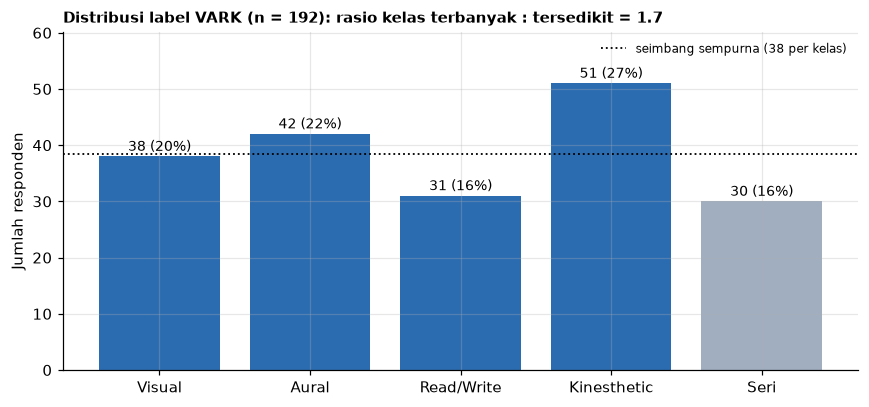

Disimpan: figures_and_outputs\A3_1_distribusi_label.png


In [12]:
frek = df[TARGET].value_counts().reindex(KELAS)
tabel_label = pd.DataFrame({"jumlah": frek, "persen": (frek / len(df) * 100).round(1)})
display(tabel_label)
simpan_tabel(tabel_label, "A3_1_distribusi_label")

rasio = frek.max() / frek.min()
print(f"Kelas terbanyak: {frek.idxmax()} ({frek.max()}) | kelas tersedikit: {frek.idxmin()} ({frek.min()}) | "
      f"rasio ketidakseimbangan = {rasio:.1f}")
print("Perkiraan jumlah per kelas di data test (20%):", {k: round(float(v), 1) for k, v in (frek * TEST_SIZE).items()})
print(f"Accuracy kalau selalu menebak kelas terbanyak: {frek.max() / len(df):.1%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
warna = [ABU if k == "Seri" else BIRU for k in KELAS]
batang = ax.bar(KELAS, frek.values, color=warna)
for b, n, p in zip(batang, frek.values, tabel_label["persen"]):
    ax.text(b.get_x() + b.get_width() / 2, n + 1, f"{n} ({p:.0f}%)", ha="center", fontsize=9)
ax.axhline(len(df) / len(KELAS), color="black", ls=":", lw=1.2, label=f"seimbang sempurna ({len(df) / len(KELAS):.0f} per kelas)")
ax.set_ylabel("Jumlah responden")
ax.set_ylim(0, frek.max() * 1.18)
ax.set_title(f"Distribusi label VARK (n = {len(df)}): rasio kelas terbanyak : tersedikit = {rasio:.1f}",
             loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
simpan_fig(fig, "A3_1_distribusi_label")

**Interpretasi A3.1**
- **Yang terlihat:** Kinesthetic paling banyak (51 orang, 27%), sedangkan **Seri (30, 16%)** dan **Read/Write (31, 16%)** paling sedikit. Rasio kelas terbanyak : tersedikit = **1,7**. Ketidakseimbangannya **ringan**: tidak ada kelas yang sangat jarang, semuanya punya minimal 30 contoh.
- **Masalah yang tetap perlu diantisipasi:**
  - Di data test (20%), setiap kelas hanya berisi **±6–10 orang**. Satu tebakan salah di kelas kecil bisa mengubah skor kelas itu sekitar 16 poin persen. Karena itu split **wajib distratifikasi** supaya kelima kelas terwakili dengan proporsi yang sama di train dan test.
  - **Accuracy saja bisa menyesatkan:** model yang selalu menebak "Kinesthetic" sudah mendapat accuracy 26,6% tanpa belajar apa pun. **Macro-F1** menghitung kelima kelas dengan bobot yang sama, sehingga kelas kecil (Seri, Read/Write) ikut diperhitungkan. Macro-F1 dipakai sebagai **metrik utama** pemilihan model.
- **Dampak ke modeling:** `class_weight="balanced"` (memberi bobot lebih pada kelas kecil) dimasukkan sebagai pilihan saat tuning di A5, dan biar cross-validation yang memutuskan dipakai atau tidak. Oversampling seperti SMOTE **tidak** dipakai: ketidakseimbangannya ringan, dan SMOTE akan membuat nilai pecahan (misalnya 0,4) yang tidak bermakna untuk fitur "dipilih/tidak dipilih".

## A3.2 Seberapa tipis selisih skor yang menentukan label?
Karena label ditentukan oleh skor **tertinggi**, responden yang skor tertinggi dan keduanya **hampir sama** berada di "perbatasan" antar kategori. Perubahan satu centang saja bisa memindahkan label mereka. Bagian ini menghitung **selisih skor tertinggi dengan skor kedua** untuk setiap responden.

label,Visual,Aural,Read/Write,Kinesthetic,Seri
selisih skor tertinggi - kedua,,,,,
0,0,0,0,0,30
1,10,14,12,9,0
2,6,5,8,11,0
3,6,8,5,10,0
4,3,5,5,8,0
>= 5,13,10,1,13,0


Disimpan: figures_and_outputs\A3_2_selisih_skor_per_label.csv
Responden dengan selisih 0-1 (Seri atau menang tipis): 75 dari 192 (39%)
Median selisih per label: {'Visual': 3.0, 'Aural': 3.0, 'Read/Write': 2.0, 'Kinesthetic': 3.0, 'Seri': 0.0}
Pada label Seri, jumlah modalitas yang sama tinggi: {'2 modalitas': 25, '3 modalitas': 4, '4 modalitas': 1}


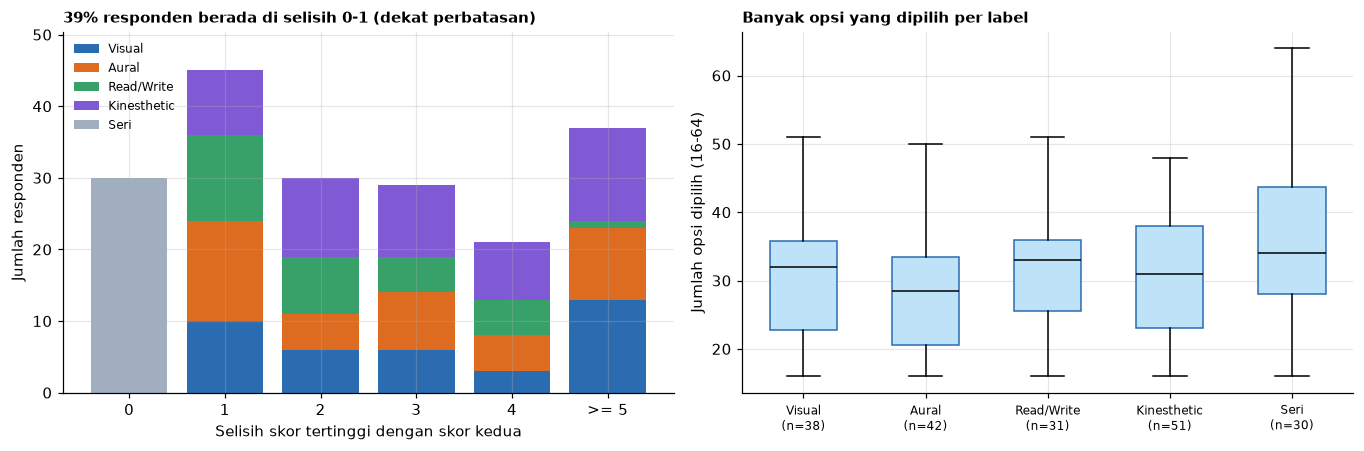

Disimpan: figures_and_outputs\A3_2_selisih_skor_dan_jumlah_opsi.png


In [13]:
df_eda = pd.DataFrame({"label": df[TARGET], "selisih": selisih_teratas,
                       "jumlah_opsi": df[FEATURE_COLS].sum(axis=1)})
tabel_selisih = pd.crosstab(df_eda["selisih"].clip(upper=5), df_eda["label"]).reindex(columns=KELAS)
tabel_selisih.index = [str(i) if i < 5 else ">= 5" for i in tabel_selisih.index]
tabel_selisih.index.name = "selisih skor tertinggi - kedua"
display(tabel_selisih)
simpan_tabel(tabel_selisih, "A3_2_selisih_skor_per_label")

n_tipis = int((df_eda["selisih"] <= 1).sum())
print(f"Responden dengan selisih 0-1 (Seri atau menang tipis): {n_tipis} dari {len(df)} ({n_tipis / len(df):.0%})")
print("Median selisih per label:", df_eda.groupby("label")["selisih"].median().reindex(KELAS).to_dict())

seri = skor[df[TARGET] == "Seri"]
n_seri_mod = seri.eq(seri.max(axis=1), axis=0).sum(axis=1).value_counts().sort_index()
print("Pada label Seri, jumlah modalitas yang sama tinggi:", {f"{k} modalitas": v for k, v in n_seri_mod.items()})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
bawah = np.zeros(len(tabel_selisih))
warna_kelas = dict(zip(KELAS, [BIRU, ORANYE, "#38a169", "#805ad5", ABU]))
for k in KELAS:
    ax1.bar(tabel_selisih.index, tabel_selisih[k], bottom=bawah, color=warna_kelas[k], label=k)
    bawah += tabel_selisih[k].values
ax1.set_ylim(0, bawah.max() * 1.12)
ax1.set_xlabel("Selisih skor tertinggi dengan skor kedua")
ax1.set_ylabel("Jumlah responden")
ax1.set_title(f"{n_tipis / len(df):.0%} responden berada di selisih 0-1 (dekat perbatasan)", loc="left", fontsize=10, fontweight="bold")
ax1.legend(frameon=False, fontsize=8)

data_box = [df_eda.loc[df_eda["label"] == k, "jumlah_opsi"] for k in KELAS]
ax2.boxplot(data_box, widths=0.55, patch_artist=True, boxprops=dict(facecolor="#bee3f8", color=BIRU),
            medianprops=dict(color="black"), flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANYE))
ax2.set_xticks(range(1, len(KELAS) + 1), [f"{k}\n(n={len(d)})" for k, d in zip(KELAS, data_box)], fontsize=8)
ax2.set_ylabel("Jumlah opsi dipilih (16-64)")
ax2.set_title("Banyak opsi yang dipilih per label", loc="left", fontsize=10, fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "A3_2_selisih_skor_dan_jumlah_opsi")

**Interpretasi A3.2**
- **Grafik kiri:** label **Seri** selalu punya selisih 0 (memang begitu definisinya). Dari 30 responden Seri, 25 berbagi skor tertinggi di 2 modalitas, 4 di 3 modalitas, dan 1 orang (ID 55) di keempatnya. Selain itu, **45 responden lain menang tipis** (selisih 1). Totalnya **75 dari 192 (39%)** berada dekat "perbatasan" antar kategori, sehingga satu centang berbeda saja bisa memindahkan label mereka.
- **Read/Write paling sering menang tipis:** median selisihnya 2, sedangkan kelas lain 3, dan hanya 1 responden Read/Write yang menang dengan selisih ≥ 5. Jadi selain Seri, Read/Write diperkirakan menjadi kelas yang paling sulit.
- **Grafik kanan:** responden Seri cenderung memilih **lebih banyak opsi** (median 34, kelas lain 28,5–33). Wajar: makin banyak opsi yang dicentang, makin besar peluang dua modalitas mendapat skor yang sama.
- **Artinya:** aturan label punya **perbatasan yang tajam**. Model tidak diberi aturan itu; ia hanya belajar dari contoh. Jadi kesalahan diperkirakan menumpuk pada responden yang selisih skornya 0–1, terutama **Seri**, karena "daerah" Seri sangat sempit (skor harus tepat sama).
- **Dampak ke modeling:** analisis kesalahan di A6 akan mengelompokkan salah tebak berdasarkan selisih skor ini, sesuai arahan panduan (*"hubungkan kesalahan dengan kelas minoritas, fitur, atau kedekatan skor kategori"*).

## A3.3 Kesimpulan EDA → keputusan modeling

**Ringkasnya:** data bersih dan semua 192 responden punya label. Kelasnya cukup seimbang, tetapi hampir 4 dari 10 responden berada dekat perbatasan antar kategori. Karena label dihitung dari X, model seharusnya bisa meniru aturan dengan cukup baik untuk responden yang "jelas", tetapi akan kesulitan pada kasus Seri dan menang tipis.

| # | Yang kami temukan | Jadi, di tahap modeling kami... |
|---|---|---|
| 1 | 192 data bersih, semua punya label, fitur tidak ada yang kosong (A2) | memakai seluruh 192 baris; pipeline tidak perlu imputer |
| 2 | 5 kelas dengan rasio 1,7; Seri dan Read/Write paling sedikit (A3.1) | membagi data dengan **stratifikasi**; memakai **macro-F1** sebagai ukuran utama; mencoba `class_weight="balanced"` saat tuning; membandingkan dengan baseline "selalu tebak kelas terbanyak" (accuracy 26,6%) |
| 3 | 39% responden berada di selisih skor 0–1 (A3.2) | memperkirakan kesalahan menumpuk di sana, dan mengeceknya di A6 dengan tabel kesalahan per selisih skor |
| 4 | Label = modalitas dengan skor tertinggi, sehingga batas antar kelas tidak sepenuhnya lurus, terutama di sekitar Seri | mencoba SVM dengan kernel **linear** dan **RBF** (bisa membentuk batas melengkung), dan Random Forest sebagai model wajib kedua. SVM butuh scaling, jadi `StandardScaler` dipasang di dalam pipeline |
| 5 | Data kecil (±153 train, ±39 test) | memilih model dengan **5-fold cross-validation bertingkat (stratified)** di data train; data test hanya dipakai **sekali** di A6 |

### Checkpoint: data siap untuk modeling
Sel ini hanya memastikan bahan untuk A4 sudah lengkap: **X** (192 × 64), **y** (192 label), tanpa nilai kosong, dan `ID` serta skor V/A/R/K disimpan terpisah (bukan fitur) untuk analisis kesalahan di A6. Pembagian train/test baru dilakukan di A4.

In [14]:
X = df[FEATURE_COLS]
y = df[TARGET]
id_all = df["ID"]                                   # hanya untuk menelusuri kesalahan di A6
skor_audit = skor.assign(selisih=selisih_teratas)   # hanya untuk analisis kesalahan, bukan fitur

assert X.shape == (192, 64) and y.shape == (192,)
assert not X.isna().any().any() and not y.isna().any()
assert list(X.columns) == FEATURE_COLS and not set(X.columns) & set(SKOR_VARK + ["ID", "IPK"])
print(f"X: {X.shape} | y: {y.shape} | kelas: {y.nunique()} | ID unik: {id_all.is_unique}")
print("Data siap masuk A4 (split & pipeline).")

X: (192, 64) | y: (192,) | kelas: 5 | ID unik: True
Data siap masuk A4 (split & pipeline).


---
# A4 – Pembagian data & pipeline

| Aturan (spesifikasi & panduan) | Cara memenuhinya |
|---|---|
| Train : test = 80 : 20 dengan `random_state = 42` | `train_test_split(test_size=TEST_SIZE, random_state=SEED)` |
| Stratifikasi bila memungkinkan | `stratify=y`: setiap kelas punya minimal 30 contoh, jadi stratifikasi **memungkinkan** dan dipakai |
| Split dibuat sebelum transformasi yang belajar dari data | Scaling hanya terjadi **di dalam pipeline** saat model di-fit |
| Kedua model memakai pembagian data yang sama | Satu `X_train`/`X_test` dan satu skema cross-validation (`cv`) untuk semua model |

## A4.1 Membagi data train dan test (stratified)
Stratifikasi membuat proporsi kelima label di data train dan test **sama** dengan data keseluruhan. Tanpa stratifikasi, kelas kecil seperti Seri bisa kebetulan hanya muncul 2–3 kali di test, sehingga skornya tidak bisa dinilai. Data test **tidak disentuh** sampai A6.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
id_train, id_test = id_all.loc[X_train.index], id_all.loc[X_test.index]   # ID hanya untuk analisis kesalahan

assert len(X_train) + len(X_test) == len(X) == 192
assert set(X_train.index).isdisjoint(X_test.index)
assert list(X_train.columns) == list(X_test.columns) == FEATURE_COLS
print(f"Train: {len(X_train)} baris ({len(X_train) / len(X):.0%}) | Test: {len(X_test)} baris ({len(X_test) / len(X):.0%}) | "
      f"random_state = {SEED}, stratify = y")

sebaran = pd.DataFrame({
    "semua (n)": y.value_counts(), "train (n)": y_train.value_counts(), "test (n)": y_test.value_counts(),
    "semua (%)": y.value_counts(normalize=True) * 100, "train (%)": y_train.value_counts(normalize=True) * 100,
    "test (%)": y_test.value_counts(normalize=True) * 100,
}).reindex(KELAS).round(1)
display(sebaran)
simpan_tabel(sebaran, "A4_1_sebaran_label_train_test")

pembagian = pd.concat([pd.DataFrame({"ID": id_train.values, "bagian": "train"}),
                       pd.DataFrame({"ID": id_test.values, "bagian": "test"})]).sort_values("ID").set_index("ID")
simpan_tabel(pembagian, "A4_1_pembagian_train_test")

Train: 153 baris (80%) | Test: 39 baris (20%) | random_state = 42, stratify = y


,semua (n),train (n),test (n),semua (%),train (%),test (%)
VARK_label,,,,,,
Visual,38,30,8,19.8,19.6,20.5
Aural,42,33,9,21.9,21.6,23.1
Read/Write,31,25,6,16.1,16.3,15.4
Kinesthetic,51,41,10,26.6,26.8,25.6
Seri,30,24,6,15.6,15.7,15.4


Disimpan: figures_and_outputs\A4_1_sebaran_label_train_test.csv
Disimpan: figures_and_outputs\A4_1_pembagian_train_test.csv


**Interpretasi A4.1**
- Data dibagi **153 train : 39 test**. Berkat stratifikasi, persentase setiap label di train dan test hampir sama dengan data keseluruhan (selisih paling besar 1,2 poin persen, pada Aural).
- Di data test, setiap kelas berisi **6–10 responden**: Visual 8, Aural 9, Read/Write 6, Kinesthetic 10, Seri 6. Jumlah ini kecil, jadi saat membaca hasil di A6 perlu diingat bahwa **satu tebakan salah di kelas Seri atau Read/Write mengubah skor kelas itu sekitar 17 poin persen**.

## A4.2 Pipeline model dan skema cross-validation
Setiap model dibungkus dalam `Pipeline`, sehingga langkah yang **belajar dari data** (`StandardScaler`) hanya di-fit pada data latih, termasuk di setiap lipatan cross-validation. Model yang disimpan di A7 juga sudah membawa preprocessing-nya, sehingga aplikasi Streamlit cukup memberi 64 fitur 0/1.

| Model | Isi pipeline | Kenapa |
|---|---|---|
| **Baseline** | `DummyClassifier(strategy="most_frequent")` | Selalu menebak kelas terbanyak di data train (Kinesthetic). Patokan minimum |
| **SVM** | `StandardScaler` → `SVC` | Model wajib. SVM mencari batas pemisah antar kelas berdasarkan jarak, sehingga fitur perlu diskalakan |
| **Random Forest** | `RandomForestClassifier(n_estimators=500, random_state=42)` | Model wajib. Pohon keputusan tidak terpengaruh skala fitur, jadi tidak perlu scaler |

**Skema cross-validation:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, yaitu **5-fold cross-validation bertingkat**. Setiap lipatan mempertahankan proporsi kelima label, sehingga kelas kecil selalu ada di setiap lipatan validasi. Objek `cv` yang sama dipakai untuk semua model dan untuk GridSearch.

**Metrik:** **macro-F1** (utama, A3.3) dan accuracy.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

PIPELINES = {
    "Baseline (kelas terbanyak)": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "SVM":                        Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "Random Forest":              Pipeline([("model", RandomForestClassifier(n_estimators=500, random_state=SEED))]),
}
SCORING = {"accuracy": "accuracy", "macro_F1": "f1_macro"}

display(pd.DataFrame({
    "langkah": [" -> ".join(type(step).__name__ for _, step in p.steps) for p in PIPELINES.values()],
    "preprocessing yang belajar dari data": ["-", "StandardScaler (di-fit hanya pada data latih)", "-"],
}, index=PIPELINES.keys()))

lipatan = pd.DataFrame(
    [{"lipatan": k + 1, "n_latih": len(tr), "n_validasi": len(va),
      **{f"{c} (validasi)": int((y_train.iloc[va] == c).sum()) for c in KELAS}}
     for k, (tr, va) in enumerate(cv.split(X_train, y_train))]).set_index("lipatan")
display(lipatan)
assert lipatan["n_validasi"].sum() == len(X_train)

,langkah,preprocessing yang belajar dari data
Baseline (kelas terbanyak),DummyClassifier,-
SVM,StandardScaler -> SVC,StandardScaler (di-fit hanya pada data latih)
Random Forest,RandomForestClassifier,-


,n_latih,n_validasi,Visual (validasi),Aural (validasi),Read/Write (validasi),Kinesthetic (validasi),Seri (validasi)
lipatan,,,,,,,
1,122,31,6,6,5,9,5
2,122,31,6,7,5,8,5
3,122,31,6,7,5,8,5
4,123,30,6,7,5,8,4
5,123,30,6,6,5,8,5


**Ringkasan A4:**
- Data dibagi **153 train : 39 test** (80 : 20, `random_state = 42`) dengan **stratifikasi**, sehingga proporsi kelima label di train dan test sama dengan data keseluruhan.
- Tiga pipeline siap: Baseline, SVM (dengan scaler di dalam pipeline), dan Random Forest.
- Semua model memakai split dan **5-fold cross-validation bertingkat** yang sama; setiap lipatan validasi berisi kelima kelas. Tidak ada transformasi yang di-fit di luar data latih, sehingga bebas *data leakage*.

---
# A5 – Training & pemilihan model

Semua langkah di bagian ini **hanya memakai data train (153 baris)** dengan 5-fold cross-validation bertingkat (`cv` dari A4). Data test belum disentuh.

**Aturan pemilihan (ditetapkan sebelum melihat hasil):** dari SVM dan Random Forest **hasil tuning**, dipilih yang **macro-F1 cross-validation-nya paling tinggi**. Model itulah yang dievaluasi di test (A6) dan disimpan (A7).

**Cara membaca tabel:**
- **macro-F1 CV** = rata-rata F1 kelima kelas pada lipatan validasi, dengan bobot sama untuk setiap kelas. Makin tinggi makin baik (0–1).
- **accuracy CV** = proporsi tebakan benar pada lipatan validasi.
- **macro-F1 train** = skor pada data yang dipakai untuk melatih. Kalau jauh lebih tinggi dari CV, model **menghafal**.

## A5.1 Baseline dan model dengan setelan default
Sebagai titik awal, baseline serta SVM dan Random Forest dengan setelan default scikit-learn dievaluasi dulu. Hasil ini menjadi pembanding untuk melihat apakah tuning di A5.2–A5.3 benar-benar membantu.

In [18]:
def evaluasi_cv(nama, model):
    """5-fold CV bertingkat di data train; kembalikan ringkasan metrik validasi dan train."""
    h = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    return pd.Series({
        "macro-F1 CV": h["test_macro_F1"].mean(), "macro-F1 CV (SD)": h["test_macro_F1"].std(),
        "accuracy CV": h["test_accuracy"].mean(), "accuracy CV (SD)": h["test_accuracy"].std(),
        "macro-F1 train": h["train_macro_F1"].mean(), "waktu fit (detik)": h["fit_time"].mean(),
    }, name=nama)

hasil_cv = pd.DataFrame([evaluasi_cv("Baseline (kelas terbanyak)", PIPELINES["Baseline (kelas terbanyak)"]),
                         evaluasi_cv("SVM (default)", PIPELINES["SVM"]),
                         evaluasi_cv("Random Forest (default)", PIPELINES["Random Forest"])])
display(hasil_cv.round(3))

,macro-F1 CV,macro-F1 CV (SD),accuracy CV,accuracy CV (SD),macro-F1 train,waktu fit (detik)
Baseline (kelas terbanyak),0.085,0.003,0.268,0.012,0.085,0.003
SVM (default),0.658,0.064,0.719,0.030,0.998,0.003
Random Forest (default),0.559,0.085,0.640,0.061,1.000,0.360


**Interpretasi A5.1**
- **Baseline** (selalu menebak "Kinesthetic") hanya mendapat macro-F1 **0,085** dan accuracy 0,27. Accuracy-nya terlihat "lumayan", tetapi macro-F1 membongkar bahwa model ini sama sekali tidak bisa mengenali empat kelas lainnya. Inilah alasan macro-F1 dipakai sebagai ukuran utama.
- Dengan setelan default saja, **SVM** sudah mencapai macro-F1 **0,658** (accuracy 0,72) dan **Random Forest** **0,559** (accuracy 0,64). Keduanya jauh di atas baseline, jadi jawaban VARK memang cukup untuk meniru aturan label. Ini wajar, karena label dihitung langsung dari jawaban yang sama.
- **macro-F1 train kedua model ≈ 1,00**, artinya model hampir hafal semua contoh latih. Untuk tugas ini skor train sempurna sebenarnya **masuk akal**: label adalah fungsi pasti dari X, jadi model yang benar-benar menangkap aturannya juga akan mendapat 1,00 di data baru. Selisih train (1,00) dan CV (0,56–0,66) menunjukkan model **belum menangkap aturan sepenuhnya**: sebagian contoh dihafal, bukan dipahami. Yang dipakai untuk memilih model tetap skor CV.

## A5.2 SVM: tuning hyperparameter dengan GridSearchCV

| Parameter | Arti sederhana | Nilai yang dicoba |
|---|---|---|
| `kernel` | Bentuk batas pemisah antar kelas: `linear` = garis/bidang lurus, `rbf` = batas yang bisa melengkung | linear, rbf |
| `C` | Seberapa keras model menghukum kesalahan di data latih. Besar = berusaha benar semua (berisiko menghafal), kecil = batas lebih longgar | linear: 0,01; 0,1; 1; 10 · rbf: 0,1; 1; 10; 100 |
| `gamma` (khusus rbf) | Seberapa jauh pengaruh satu titik data. Besar = batas sangat berliku (berisiko menghafal) | `scale` (default), 0,001; 0,01; 0,1 |
| `class_weight` | `balanced` memberi bobot lebih besar pada kelas yang sedikit (Seri, Read/Write) | None, balanced |

Total **40 kombinasi × 5 lipatan = 200 kali training**, semuanya di data train. Kombinasi dengan macro-F1 CV tertinggi dipilih, lalu dilatih ulang di seluruh 153 baris train (`refit`).

Jumlah kombinasi dicoba: 40
Parameter terbaik SVM: {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}


,kernel,C,gamma,class_weight,macro-F1 CV,macro-F1 CV (SD),accuracy CV,macro-F1 train
1,rbf,1,scale,balanced,0.667,0.070,0.700,1.000
2,rbf,1,scale,None,0.658,0.064,0.719,0.998
3,rbf,1,0.01,balanced,0.645,0.062,0.680,0.994
4,rbf,1,0.01,None,0.642,0.058,0.706,0.955
5,rbf,10,scale,None,0.620,0.049,0.667,1.000
6,rbf,10,scale,balanced,0.620,0.049,0.667,1.000
7,rbf,100,scale,balanced,0.620,0.049,0.667,1.000
8,rbf,100,scale,None,0.620,0.049,0.667,1.000
9,linear,0.01,None,None,0.619,0.074,0.674,0.873
10,linear,0.01,None,balanced,0.616,0.059,0.660,0.899


Disimpan: figures_and_outputs\A5_2_gridsearch_svm.csv
Terbaik kernel linear: macro-F1 CV 0.619 | terbaik kernel rbf: macro-F1 CV 0.667


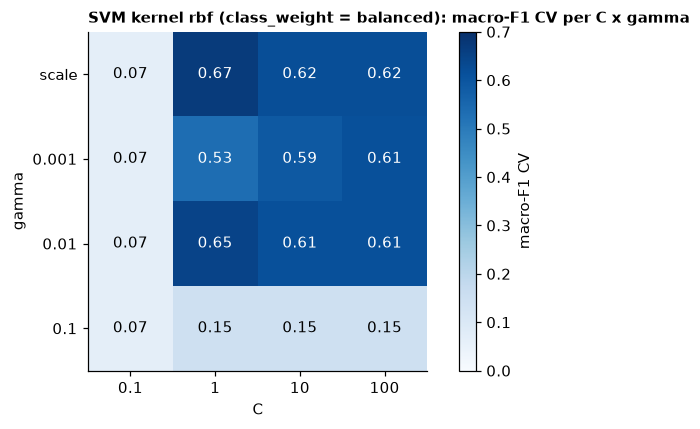

Disimpan: figures_and_outputs\A5_2_tuning_svm.png


In [19]:
GRID_SVM = [
    {"model__kernel": ["linear"], "model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.001, 0.01, 0.1],
     "model__class_weight": [None, "balanced"]},
]
grid_svm = GridSearchCV(PIPELINES["SVM"], GRID_SVM, cv=cv, scoring=SCORING, refit="macro_F1", return_train_score=True)
grid_svm.fit(X_train, y_train)

def teks_param(v):
    """Ubah nilai parameter menjadi teks rapi: None/kosong -> 'None', angka -> '1', '0.01', dst."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "None"
    if isinstance(v, (int, float, np.integer, np.floating)):
        return f"{v:g}"
    return str(v)

def tabel_hasil_grid(grid, kolom_param):
    h = pd.DataFrame(grid.cv_results_)
    t = pd.DataFrame({k.replace("model__", ""): h[f"param_{k}"].map(teks_param) for k in kolom_param})
    t["macro-F1 CV"], t["macro-F1 CV (SD)"] = h["mean_test_macro_F1"], h["std_test_macro_F1"]
    t["accuracy CV"], t["macro-F1 train"] = h["mean_test_accuracy"], h["mean_train_macro_F1"]
    t = t.sort_values("macro-F1 CV", ascending=False).reset_index(drop=True)
    t.index += 1
    return t

tabel_svm = tabel_hasil_grid(grid_svm, ["model__kernel", "model__C", "model__gamma", "model__class_weight"])
print(f"Jumlah kombinasi dicoba: {len(tabel_svm)}")
print("Parameter terbaik SVM:", {k.replace("model__", ""): v for k, v in grid_svm.best_params_.items()})
display(tabel_svm.head(10).round(3))
simpan_tabel(tabel_svm.round(4), "A5_2_gridsearch_svm")

terbaik_linear = tabel_svm[tabel_svm["kernel"] == "linear"].iloc[0]
terbaik_rbf = tabel_svm[tabel_svm["kernel"] == "rbf"].iloc[0]
print(f"Terbaik kernel linear: macro-F1 CV {terbaik_linear['macro-F1 CV']:.3f} | "
      f"terbaik kernel rbf: macro-F1 CV {terbaik_rbf['macro-F1 CV']:.3f}")

# Grafik: macro-F1 CV kernel rbf untuk setiap C x gamma (class_weight terbaik)
cw_terbaik = str(grid_svm.best_params_.get("model__class_weight"))
peta = (tabel_svm[(tabel_svm["kernel"] == "rbf") & (tabel_svm["class_weight"] == cw_terbaik)]
        .pivot_table(index="gamma", columns="C", values="macro-F1 CV"))
peta = peta.reindex(index=["scale", "0.001", "0.01", "0.1"], columns=["0.1", "1", "10", "100"])
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(peta.values, cmap="Blues", vmin=0, vmax=max(0.7, np.nanmax(peta.values)))
for i in range(peta.shape[0]):
    for j in range(peta.shape[1]):
        v = peta.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10, color="white" if v > 0.5 else "black")
ax.set_xticks(range(4), peta.columns); ax.set_yticks(range(4), peta.index)
ax.set_xlabel("C"); ax.set_ylabel("gamma"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="macro-F1 CV")
ax.set_title(f"SVM kernel rbf (class_weight = {cw_terbaik}): macro-F1 CV per C x gamma", loc="left", fontsize=10, fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "A5_2_tuning_svm")

**Interpretasi A5.2**
- **Parameter terbaik:** kernel **rbf**, `C = 1`, `gamma = "scale"`, `class_weight = "balanced"`, macro-F1 CV **0,667** (SD 0,070). Ini hanya sedikit lebih tinggi dari SVM default (0,658); bedanya jauh lebih kecil dari SD antar lipatan. Jadi setelan default SVM sudah hampir optimal, dan tuning terutama **memastikan** bahwa tidak ada setelan lain yang jauh lebih baik.
- **Kernel rbf lebih baik dari linear** (0,667 vs 0,619). Label ditentukan oleh skor *tertinggi* di antara empat modalitas, ditambah kelas Seri yang hanya muncul kalau skor tepat sama. Batas seperti itu tidak sepenuhnya lurus, sehingga kernel yang bisa membentuk batas melengkung lebih cocok.
- **Peta C × gamma:**
  - `C = 0,1` selalu buruk (0,07): rem terlalu kuat, sehingga model hampir selalu menebak satu kelas saja, mirip baseline.
  - `gamma = 0,1` juga buruk (0,15): setiap titik data hanya berpengaruh di sekitarnya sendiri, sehingga model menghafal contoh latih dan gagal di data baru.
  - Hasil terbaik ada di tengah (`C = 1`, `gamma` scale atau 0,01). Menaikkan `C` ke 10–100 tidak membantu (0,59–0,62).
- `class_weight = "balanced"` hanya menambah 0,009 dibanding tanpa pembobotan. Wajar, karena ketidakseimbangan kelasnya ringan (A3.1).

## A5.3 Random Forest: tuning hyperparameter dengan GridSearchCV

| Parameter | Arti sederhana | Nilai yang dicoba |
|---|---|---|
| `max_depth` | Kedalaman maksimum pohon | None (bebas, default), 10 |
| `min_samples_leaf` | Minimal berapa responden dalam satu daun | 1 (default), 2, 4 |
| `max_features` | Bagian fitur yang dilihat di setiap percabangan | `sqrt` (8 fitur, default), 0.3 (19 fitur) |
| `class_weight` | `balanced` memberi bobot lebih besar pada kelas yang sedikit | None, balanced |

Total **24 kombinasi × 5 lipatan = 120 kali training**. `n_estimators = 500` dibuat tetap seperti di Notebook B.

In [20]:
GRID_RF = {
    "model__max_depth": [None, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.3],
    "model__class_weight": [None, "balanced"],
}
grid_rf = GridSearchCV(PIPELINES["Random Forest"], GRID_RF, cv=cv, scoring=SCORING, refit="macro_F1", return_train_score=True)
grid_rf.fit(X_train, y_train)

tabel_rf = tabel_hasil_grid(grid_rf, ["model__max_depth", "model__min_samples_leaf", "model__max_features", "model__class_weight"])
print(f"Jumlah kombinasi dicoba: {len(tabel_rf)}")
print("Parameter terbaik RF:", {k.replace("model__", ""): v for k, v in grid_rf.best_params_.items()})
display(tabel_rf.head(10).round(3))
simpan_tabel(tabel_rf.round(4), "A5_3_gridsearch_rf")

Jumlah kombinasi dicoba: 24
Parameter terbaik RF: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2}


,max_depth,min_samples_leaf,max_features,class_weight,macro-F1 CV,macro-F1 CV (SD),accuracy CV,macro-F1 train
1,10,2,sqrt,balanced,0.590,0.042,0.640,1.000
2,None,2,sqrt,balanced,0.590,0.042,0.640,1.000
3,None,4,sqrt,balanced,0.580,0.052,0.627,0.985
4,10,4,sqrt,balanced,0.580,0.052,0.627,0.985
5,None,1,sqrt,balanced,0.562,0.074,0.628,1.000
6,None,1,sqrt,None,0.559,0.085,0.640,1.000
7,10,1,sqrt,None,0.559,0.085,0.640,1.000
8,10,2,sqrt,None,0.559,0.109,0.647,1.000
9,None,2,sqrt,None,0.559,0.109,0.647,1.000
10,10,1,sqrt,balanced,0.557,0.066,0.621,1.000


Disimpan: figures_and_outputs\A5_3_gridsearch_rf.csv


**Interpretasi A5.3**
- **Parameter terbaik:** `class_weight = "balanced"`, `min_samples_leaf = 2`, `max_features = "sqrt"`, macro-F1 CV **0,590** (SD 0,042), naik dari RF default (0,559). `max_depth = None` dan `10` memberi skor yang persis sama; GridSearch mengambil yang muncul lebih dulu (None).
- **Yang paling berpengaruh:** `class_weight = "balanced"` (4 kombinasi teratas semuanya balanced) dan `max_features = "sqrt"` (tidak ada kombinasi `0.3` di 10 besar). Pohon yang hanya melihat sebagian kecil fitur di setiap percabangan menghasilkan hutan yang lebih beragam.
- Walaupun sudah di-tuning, RF tetap **di bawah SVM default**. Kemungkinan penyebabnya: label adalah hasil *penjumlahan* 16 indikator per modalitas lalu dibandingkan. Pohon keputusan hanya bisa memotong satu fitur per langkah ("Q01_K = 1?"), sehingga butuh banyak sekali percabangan untuk meniru "jumlah K lebih besar dari jumlah V", dan 153 contoh tidak cukup untuk itu.

## A5.4 Perbandingan model (cross-validation di data train)

,macro-F1 CV,macro-F1 CV (SD),accuracy CV,accuracy CV (SD),macro-F1 train,waktu fit (detik)
Baseline (kelas terbanyak),0.085,0.003,0.268,0.012,0.085,0.003
SVM (default),0.658,0.064,0.719,0.030,0.998,0.003
SVM (tuning),0.667,0.070,0.700,0.054,1.000,0.006
Random Forest (default),0.559,0.085,0.640,0.061,1.000,0.360
Random Forest (tuning),0.590,0.042,0.640,0.021,1.000,0.368


Disimpan: figures_and_outputs\A5_4_perbandingan_cv.csv
F1 per kelas (prediksi cross-validation di data train):


,SVM (tuning),Random Forest (tuning),jumlah di train
Visual,0.780,0.787,30
Aural,0.706,0.594,33
Read/Write,0.609,0.444,25
Kinesthetic,0.841,0.835,41
Seri,0.400,0.311,24


Disimpan: figures_and_outputs\A5_4_f1_per_kelas_cv.csv


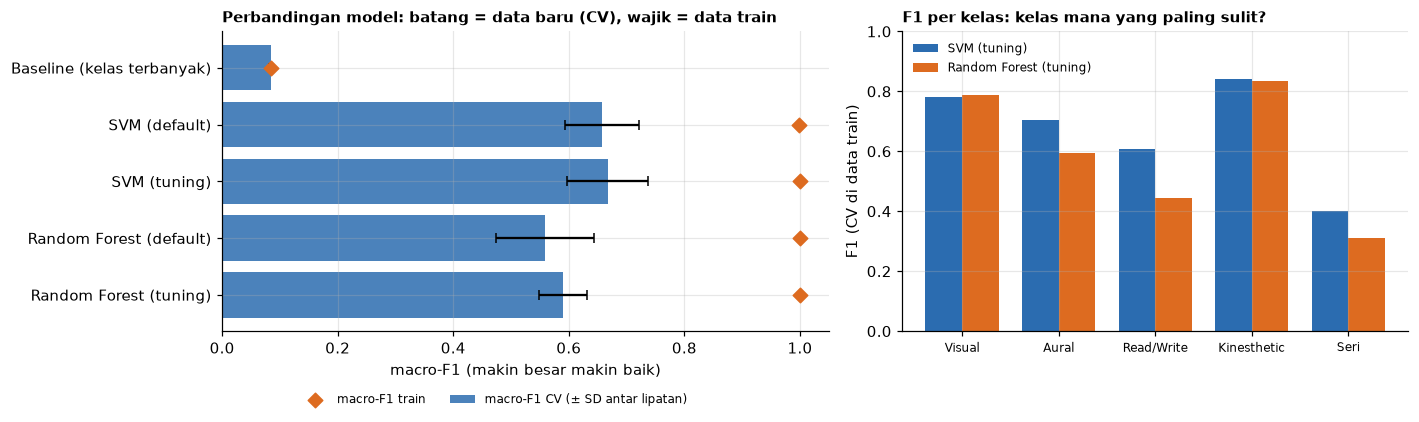

Disimpan: figures_and_outputs\A5_4_perbandingan_model_cv.png


In [21]:
hasil_cv = pd.concat([hasil_cv.T, evaluasi_cv("SVM (tuning)", grid_svm.best_estimator_),
                      evaluasi_cv("Random Forest (tuning)", grid_rf.best_estimator_)], axis=1).T.astype(float)
urutan = ["Baseline (kelas terbanyak)", "SVM (default)", "SVM (tuning)", "Random Forest (default)", "Random Forest (tuning)"]
hasil_cv = hasil_cv.loc[urutan]
display(hasil_cv.round(3))
simpan_tabel(hasil_cv.round(4), "A5_4_perbandingan_cv")

# F1 per kelas dari prediksi cross-validation (data train), untuk melihat kelas mana yang sulit
f1_kelas = pd.DataFrame({
    nama: f1_score(y_train, cross_val_predict(model, X_train, y_train, cv=cv), labels=KELAS, average=None)
    for nama, model in [("SVM (tuning)", grid_svm.best_estimator_), ("Random Forest (tuning)", grid_rf.best_estimator_)]
}, index=KELAS)
f1_kelas["jumlah di train"] = y_train.value_counts().reindex(KELAS)
print("F1 per kelas (prediksi cross-validation di data train):")
display(f1_kelas.round(3))
simpan_tabel(f1_kelas.round(4), "A5_4_f1_per_kelas_cv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.2, 1]})
posisi = np.arange(len(urutan))
ax1.barh(posisi, hasil_cv["macro-F1 CV"], xerr=hasil_cv["macro-F1 CV (SD)"], color=BIRU, alpha=0.85,
         error_kw=dict(ecolor="black", capsize=3), label="macro-F1 CV (± SD antar lipatan)")
ax1.scatter(hasil_cv["macro-F1 train"], posisi, color=ORANYE, marker="D", s=45, zorder=3, label="macro-F1 train")
ax1.set_yticks(posisi, urutan); ax1.invert_yaxis(); ax1.set_xlim(0, 1.05)
ax1.set_xlabel("macro-F1 (makin besar makin baik)")
ax1.set_title("Perbandingan model: batang = data baru (CV), wajik = data train", loc="left", fontsize=10, fontweight="bold")
ax1.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=2)

lebar = 0.38
for k, (nama, warna) in enumerate(zip(["SVM (tuning)", "Random Forest (tuning)"], [BIRU, ORANYE])):
    ax2.bar(np.arange(len(KELAS)) + (k - 0.5) * lebar, f1_kelas[nama], lebar, color=warna, label=nama)
ax2.set_xticks(range(len(KELAS)), KELAS, fontsize=8); ax2.set_ylim(0, 1)
ax2.set_ylabel("F1 (CV di data train)")
ax2.set_title("F1 per kelas: kelas mana yang paling sulit?", loc="left", fontsize=10, fontweight="bold")
ax2.legend(frameon=False, fontsize=8)
fig.tight_layout()
simpan_fig(fig, "A5_4_perbandingan_model_cv")

**Interpretasi A5.4**
- **SVM (tuning) unggul:** macro-F1 CV **0,667** vs Random Forest (tuning) **0,590**, dan accuracy 0,70 vs 0,64. Selisih macro-F1 (0,077) sekitar 1–2 kali SD antar lipatan, jadi keunggulan SVM cukup konsisten, walaupun tidak besar.
- **F1 per kelas** sesuai dugaan di A3.2:
  - Paling mudah: **Kinesthetic** (0,84) dan **Visual** (0,78–0,79). Keduanya punya banyak responden yang menang dengan selisih besar.
  - Paling sulit: **Seri** (SVM 0,40, RF 0,31), lalu **Read/Write** (SVM 0,61, RF 0,44). Seri hanya terjadi kalau skor tepat sama, dan Read/Write paling sering menang tipis.
  - SVM lebih baik di kelas-kelas sulit (Aural, Read/Write, Seri), dan di situlah selisih macro-F1 kedua model berasal.
- **Wajik oranye di 1,00 untuk keempat model** menunjukkan semua model hafal data train. Yang membedakan adalah seberapa baik mereka di data baru (batang biru).

## A5.5 Model yang dipilih untuk evaluasi test
Sesuai aturan di awal A5: dari SVM dan Random Forest hasil tuning, dipilih yang macro-F1 CV-nya paling tinggi.

In [22]:
kandidat = hasil_cv.loc[["SVM (tuning)", "Random Forest (tuning)"], "macro-F1 CV"]
NAMA_TERPILIH = kandidat.idxmax()
MODEL_FINAL = {"SVM (tuning)": grid_svm.best_estimator_,              # keduanya sudah di-refit
               "Random Forest (tuning)": grid_rf.best_estimator_}     # di seluruh 153 baris train
PARAM_FINAL = {"SVM (tuning)": grid_svm.best_params_, "Random Forest (tuning)": grid_rf.best_params_}

print("macro-F1 CV kandidat:", kandidat.round(3).to_dict())
print("Model terpilih :", NAMA_TERPILIH)
print("Parameter      :", {k.replace("model__", ""): v for k, v in PARAM_FINAL[NAMA_TERPILIH].items()})

macro-F1 CV kandidat: {'SVM (tuning)': 0.667, 'Random Forest (tuning)': 0.59}
Model terpilih : SVM (tuning)
Parameter      : {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}


**Keputusan A5.5**
- **SVM (tuning)** dipilih karena macro-F1 CV-nya (0,667) lebih tinggi daripada Random Forest (0,590), sesuai aturan yang ditetapkan di awal A5.
- Parameter: `kernel = "rbf"`, `C = 1`, `gamma = "scale"`, `class_weight = "balanced"`, dengan `StandardScaler` di dalam pipeline. Model ini sudah dilatih ulang di seluruh 153 baris train (`refit`) dan akan disimpan di A7 sebagai `Model_klasifikasi.joblib`.
- **Langkah berikutnya (A6):** Baseline, SVM, dan Random Forest dievaluasi **satu kali** pada 39 baris test, lengkap dengan accuracy, macro-F1, confusion matrix, dan analisis contoh salah prediksi.